# Notebook 6: Sell now or store? Decision simulation

**Inputs:** `data/predictions.csv` (Notebook 5) and `data/market_month.csv` (Notebook 3)
**Outputs:** `data/simulation_summary.csv`, `data/simulation_events.csv`, `data/montecarlo_draws.csv`

**Research question RQ4:** does following the price forecast earn a farmer more than selling at harvest or storing for
a fixed number of weeks, **after storage losses and costs**?

Notebook 5 measured forecast **accuracy**. Studies outside agriculture (Gammelli et al.; Theodorou et al., 2025) found
that more accurate forecasts do not always lead to better decisions. This notebook measures the forecast's **value**:
rupees per quintal, for real harvest-time decisions in the 2020-2026 test period that the models never saw.

**How this simulation meets the project's simulation requirements**

| Requirement | Where |
| --- | --- |
| 1. Inputs and controllable parameters | Section 2: storage loss, storage rent, interest rate, horizon |
| 2. Baseline scenario | Section 3: *sell at harvest* |
| 3. Alternative scenarios and interventions | Sections 2-3: four storage scenarios per crop, seven decision rules |
| 4. Assumptions | Section 2 (with sources) and Section 12 |
| 5. Procedure | Section 4: replay every harvest-time decision in the test period |
| 6. Outputs and indicators | Sections 5-6: gain per quintal, chance of loss, worst 5%, share of the best possible gain |
| 7. Uncertainty and sensitivity | Sections 7-9: year bootstrap, Monte Carlo over assumptions, sensitivity grid |
| 8. Validation and sanity checks | Section 4 |
| 9. The decision a stakeholder can make | Sections 10-12 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

SEED = 42
H = np.array([4, 8, 12])                    # storage horizons in weeks
MONTHS_STORED = H / 4.345                   # weeks -> months
CROPS = ["Onion", "Maize"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CROP_COLOR = {"Maize": BLUE, "Onion": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10,
})
pd.set_option("display.width", 170)

pred = pd.read_csv("../data/predictions.csv", parse_dates=["week"])
mm = pd.read_csv("../data/market_month.csv")
print(f"Test-period market-weeks: {len(pred):,} ({pred['week'].min().date()} to {pred['week'].max().date()})")

Test-period market-weeks: 15,038 (2019-11-18 to 2026-04-13)


## 1. The decisions to simulate

A farmer decides at harvest time, when prices are usually lowest and everyone is selling. The **harvest window** for
each crop is the three cheapest months of the year, found from the **training years (2003-2015)** of Notebook 3, so
the test period is not used to pick it.

A **decision event** is one market in one week of the harvest window, in the test period, where:
- the price that week was actually reported (the farmer can see it), and
- the price 4, 8 and 12 weeks later is known, so every strategy can be scored on the **same** events.

Each event stands for a farmer with 1 quintal (100 kg) to sell. Results are in rupees per quintal.

In [2]:
harvest_months = {}
for crop in CROPS:
    s = mm[(mm["commodity"] == crop) & mm["full_year"] & (mm["year"] <= 2015)]
    harvest_months[crop] = sorted(s.groupby("month")["seasonal_rel"].median().nsmallest(3).index.tolist())
print("Harvest window (3 cheapest months, 2003-2015):", {c: [MONTH_NAMES[m - 1] for m in v] for c, v in harvest_months.items()})

events = {}
for crop in CROPS:
    e = pred[(pred["commodity"] == crop) & pred["week"].dt.month.isin(harvest_months[crop]) & pred["price"].notna()]
    e = e.dropna(subset=[f"target_{h}w" for h in H] + [f"pred_{h}w_best" for h in H] + [f"q10_{h}w" for h in H])
    e = e.assign(season=e["week"].dt.year).reset_index(drop=True)
    events[crop] = e
    print(f"{crop}: {len(e):,} decision events in {e['market'].nunique()} markets; "
          f"by season: {e['season'].value_counts().sort_index().to_dict()}; mean harvest price Rs {e['price_filled'].mean():,.0f}/quintal")

Harvest window (3 cheapest months, 2003-2015): {'Onion': ['Mar', 'Apr', 'May'], 'Maize': ['Jan', 'Feb', 'Mar']}
Onion: 1,006 decision events in 18 markets; by season: {2020: 179, 2021: 198, 2022: 194, 2023: 184, 2024: 160, 2025: 91}; mean harvest price Rs 1,419/quintal
Maize: 1,862 decision events in 48 markets; by season: {2020: 570, 2021: 309, 2022: 312, 2023: 310, 2024: 226, 2025: 97, 2026: 38}; mean harvest price Rs 1,836/quintal


## 2. The economics of storing, and the scenarios

If a farmer stores for *h* weeks instead of selling now at price $P_t$, their **net gain per quintal** is

$$\text{gain}_h = \underbrace{P_{t+h} \times (1-\ell)^{m}}_{\text{sale of what is left}} \; - \; \underbrace{c \times m}_{\text{storage rent}} \; - \; \underbrace{P_t \times r \times h/52}_{\text{interest on money not received}} \; - \; P_t$$

where $m = h / 4.345$ is the number of months stored, $\ell$ is the **share of the crop lost per month** (weight loss,
rotting, sprouting, pests), $c$ is the **storage rent** in Rs per quintal per month, and $r$ is the yearly **interest
rate**. Selling now has a gain of 0 by definition.

**Evidence for the assumptions**

| Parameter | Evidence | Values used |
| --- | --- | --- |
| Onion loss in ventilated farm storage | ICAR: losses up to 42-46% in four months in low-cost and bottom-ventilated structures | about 10% per month |
| Onion loss in cold storage | ICAR: about 5% in four months at 0 °C | about 1.25% per month |
| Onion loss in well-managed storage | between the two (assumption: sorted, cured bulbs, good ventilation) | 5% per month |
| Maize loss | total post-harvest loss of about 6% across all stages (ICRIER-ADMI survey), so storage is a part of that | 0.5% (warehouse) to 3% (poor storage) per month |
| Storage rent | no single published figure for Karnataka; set as an assumption and varied in Sections 8-9 | onion Rs 5-50, maize Rs 0-10 per quintal per month |
| Interest rate | short-term crop loans are commonly around 7% a year; informal credit costs more | 7% a year, varied 4-12% |

These values are **assumptions supported by published figures, not measurements of Karnataka farms**. That is why
Sections 8 and 9 vary every one of them.

In [3]:
SCENARIOS = {
    "Onion": {
        "No costs (price effect only)": dict(loss=0.0, rent=0, rate=0.0),
        "Farm ventilated storage": dict(loss=0.10, rent=5, rate=0.07),
        "Well-managed storage": dict(loss=0.05, rent=15, rate=0.07),
        "Cold storage": dict(loss=0.0125, rent=50, rate=0.07),
    },
    "Maize": {
        "No costs (price effect only)": dict(loss=0.0, rent=0, rate=0.0),
        "Poor home storage": dict(loss=0.03, rent=0, rate=0.07),
        "Home storage in bags": dict(loss=0.015, rent=0, rate=0.07),
        "Warehouse": dict(loss=0.005, rent=10, rate=0.07),
    },
}
MAIN_SCENARIO = {"Onion": "Farm ventilated storage", "Maize": "Home storage in bags"}
pd.DataFrame([{"crop": c, "scenario": s, "loss % per month": 100 * v["loss"], "rent Rs/q/month": v["rent"],
               "interest % a year": 100 * v["rate"], "main scenario": s == MAIN_SCENARIO[c]}
              for c in CROPS for s, v in SCENARIOS[c].items()])

,crop,scenario,loss % per month,rent Rs/q/month,interest % a year,main scenario
0,Onion,No costs (price effect only),0.00,0,0.0,False
1,Onion,Farm ventilated storage,10.00,5,7.0,True
2,Onion,Well-managed storage,5.00,15,7.0,False
3,Onion,Cold storage,1.25,50,7.0,False
4,Maize,No costs (price effect only),0.00,0,0.0,False
5,Maize,Poor home storage,3.00,0,7.0,False
6,Maize,Home storage in bags,1.50,0,7.0,True
7,Maize,Warehouse,0.50,10,7.0,False


## 3. The decision rules (strategies)

Every rule chooses one of four actions for each event: **sell now**, or **store 4, 8 or 12 weeks**. Every rule uses only
information available in the decision week.

| Rule | How it decides | Represents |
| --- | --- | --- |
| **Sell at harvest** | always sell now | the baseline: what most small farmers do |
| **Always store 4 / 8 / 12 weeks** | the same fixed storage period every time | a fixed calendar habit |
| **Seasonal rule** | expected change = the market's typical seasonal change (training years); choose the action with the highest expected net gain | an experienced farmer who knows the season |
| **Forecast rule** | same, but the expected change is the Notebook 5 model's forecast | the project's decision tool |
| **Risk-aware forecast** | like the forecast rule, but only allows storage options whose **pessimistic outcome** (10th percentile of the conformal interval) loses less than 10% of the crop's value | a farmer who cannot afford a big loss |
| **Perfect foresight** | chooses the action that was actually best, knowing the future | the upper limit: no real rule can do better |

All rules use the same cost assumptions as the scenario, so they differ only in their view of future prices.

## 4. The simulation engine and sanity checks

In [4]:
def net_gain(price_now, log_change, loss, rent, rate):
    # net gain vs selling now, Rs per quintal, for storing 4, 8, 12 weeks. log_change has one column per horizon.
    keep = (1 - loss) ** MONTHS_STORED
    return (price_now[:, None] * np.exp(log_change) * keep
            - rent * MONTHS_STORED
            - price_now[:, None] * rate * H / 52
            - price_now[:, None])

def with_sell(g):
    # add the 'sell now' option (gain 0) as column 0
    return np.column_stack([np.zeros(len(g)), g])

def simulate(e, loss, rent, rate):
    # returns {rule: (action index per event, realised net gain per event)}
    P = e["price_filled"].to_numpy()
    actual = with_sell(net_gain(P, e[[f"target_{h}w" for h in H]].to_numpy(), loss, rent, rate))
    expected_seasonal = with_sell(net_gain(P, e[[f"base_seasonal_{h}w" for h in H]].to_numpy(), loss, rent, rate))
    expected_forecast = with_sell(net_gain(P, e[[f"pred_{h}w_best" for h in H]].to_numpy(), loss, rent, rate))
    pessimistic = with_sell(net_gain(P, e[[f"q10_{h}w" for h in H]].to_numpy(), loss, rent, rate))
    risk_ok = pessimistic >= -0.10 * P[:, None]
    risk_ok[:, 0] = True
    choices = {
        "Sell at harvest": np.zeros(len(e), dtype=int),
        "Always store 4 weeks": np.full(len(e), 1),
        "Always store 8 weeks": np.full(len(e), 2),
        "Always store 12 weeks": np.full(len(e), 3),
        "Seasonal rule": expected_seasonal.argmax(axis=1),
        "Forecast rule": expected_forecast.argmax(axis=1),
        "Risk-aware forecast": np.where(risk_ok, expected_forecast, -np.inf).argmax(axis=1),
        "Perfect foresight": actual.argmax(axis=1),
    }
    rows = np.arange(len(e))
    return {rule: (ch, actual[rows, ch]) for rule, ch in choices.items()}, P

RULES = ["Sell at harvest", "Always store 4 weeks", "Always store 8 weeks", "Always store 12 weeks",
         "Seasonal rule", "Forecast rule", "Risk-aware forecast", "Perfect foresight"]

# ---- Sanity checks ----
for crop in CROPS:
    res, P = simulate(events[crop], **SCENARIOS[crop]["Farm ventilated storage" if crop == "Onion" else "Home storage in bags"])
    assert np.all(res["Sell at harvest"][1] == 0), "selling now must give exactly 0"
    assert np.all(res["Perfect foresight"][1] >= 0), "perfect foresight can never do worse than selling now"
    for rule in RULES:
        assert np.all(res[rule][1] <= res["Perfect foresight"][1] + 1e-9), f"{rule} beat perfect foresight"
    # extreme losses: no sensible rule should store
    res_extreme, _ = simulate(events[crop], loss=0.6, rent=0, rate=0.07)
    print(f"{crop}: with 60% loss per month, the forecast rule stores in "
          f"{100 * (res_extreme['Forecast rule'][0] > 0).mean():.1f}% of events (should be about 0)")
    # with no costs, the 12-week fixed rule should reproduce the price change from Notebooks 3 and 5
    res0, _ = simulate(events[crop], loss=0, rent=0, rate=0)
    median_pct = 100 * np.median(res0["Always store 12 weeks"][1] / P)
    print(f"{crop}: with no costs, median gain from always storing 12 weeks = {median_pct:.1f}% of the harvest price")
print("All sanity checks passed.")

Onion: with 60% loss per month, the forecast rule stores in 0.0% of events (should be about 0)
Onion: with no costs, median gain from always storing 12 weeks = 25.0% of the harvest price
Maize: with 60% loss per month, the forecast rule stores in 0.0% of events (should be about 0)
Maize: with no costs, median gain from always storing 12 weeks = -0.1% of the harvest price
All sanity checks passed.


**What the checks confirm.** Selling now always scores exactly 0; no rule ever beats perfect foresight; perfect
foresight never loses; and with absurdly high losses the forecast rule stops storing. With no costs, the price gain
from always storing 12 weeks is in line with what Notebook 3 (H2) found from monthly data. The engine behaves as the
economics says it should.

## 5. Results: rupees per quintal, by scenario

In [5]:
def summarise(res, P):
    oracle = res["Perfect foresight"][1].mean()
    out = []
    for rule in RULES:
        ch, g = res[rule]
        out.append({"rule": rule, "mean gain Rs/q": g.mean(), "mean gain % of price": 100 * g.mean() / P.mean(),
                    "median gain Rs/q": np.median(g), "chance of doing worse than selling %": 100 * (g < 0).mean(),
                    "worst 5% (Rs/q)": np.percentile(g, 5), "stored in % of events": 100 * (ch > 0).mean(),
                    "share of perfect-foresight gain %": 100 * g.mean() / oracle if oracle > 0 else np.nan})
    return pd.DataFrame(out)

summary_rows = []
for crop in CROPS:
    for scen, params in SCENARIOS[crop].items():
        res, P = simulate(events[crop], **params)
        summary_rows.append(summarise(res, P).assign(crop=crop, scenario=scen))
summary = pd.concat(summary_rows, ignore_index=True)

for crop in CROPS:
    print(f"=== {crop}: main scenario '{MAIN_SCENARIO[crop]}' ===")
    display(summary[(summary["crop"] == crop) & (summary["scenario"] == MAIN_SCENARIO[crop])]
            .drop(columns=["crop", "scenario"]).round(1))

=== Onion: main scenario 'Farm ventilated storage' ===


,rule,mean gain Rs/q,mean gain % of price,median gain Rs/q,chance of doing worse than selling %,worst 5% (Rs/q),stored in % of events,share of perfect-foresight gain %
8,Sell at harvest,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,Always store 4 weeks,-164.5,-11.6,-134.2,65.9,-955.0,100.0,-85.2
10,Always store 8 weeks,-204.2,-14.4,-133.6,60.2,-1300.0,100.0,-105.8
11,Always store 12 weeks,-202.6,-14.3,-115.4,59.8,-1320.7,100.0,-104.9
12,Seasonal rule,9.1,0.6,0.0,25.3,-538.8,55.1,4.7
13,Forecast rule,20.0,1.4,0.0,26.0,-508.5,56.9,10.4
14,Risk-aware forecast,5.2,0.4,0.0,0.1,0.0,1.8,2.7
15,Perfect foresight,193.1,13.6,40.7,0.0,0.0,54.6,100.0


=== Maize: main scenario 'Home storage in bags' ===


,rule,mean gain Rs/q,mean gain % of price,median gain Rs/q,chance of doing worse than selling %,worst 5% (Rs/q),stored in % of events,share of perfect-foresight gain %
48,Sell at harvest,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49,Always store 4 weeks,-44.7,-2.4,-43.3,63.0,-328.5,100.0,-51.5
50,Always store 8 weeks,-96.6,-5.3,-85.6,66.6,-500.8,100.0,-111.3
51,Always store 12 weeks,-133.2,-7.3,-124.5,67.9,-551.4,100.0,-153.6
52,Seasonal rule,-32.7,-1.8,0.0,28.2,-376.8,44.0,-37.6
53,Forecast rule,26.7,1.5,0.0,19.1,-141.3,49.1,30.7
54,Risk-aware forecast,16.8,0.9,0.0,13.6,-83.9,34.3,19.3
55,Perfect foresight,86.7,4.7,0.0,0.0,0.0,48.0,100.0


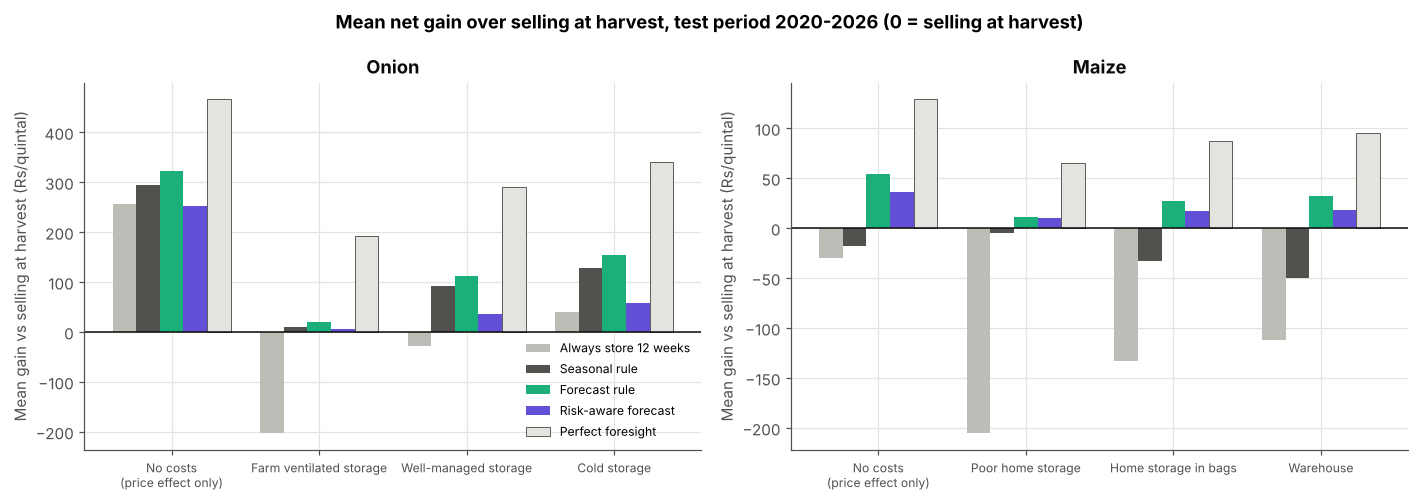

In [6]:
SHOW = ["Always store 12 weeks", "Seasonal rule", "Forecast rule", "Risk-aware forecast", "Perfect foresight"]
rule_color = {"Always store 12 weeks": "#bdbcb7", "Seasonal rule": MUTED, "Forecast rule": AQUA,
              "Risk-aware forecast": VIOLET, "Perfect foresight": "#e4e3df"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, crop in zip(axes, CROPS):
    scen_names = list(SCENARIOS[crop])
    width = 0.16
    for i, rule in enumerate(SHOW):
        vals = [summary[(summary["crop"] == crop) & (summary["scenario"] == s) & (summary["rule"] == rule)]["mean gain Rs/q"].iloc[0]
                for s in scen_names]
        ax.bar(np.arange(len(scen_names)) + (i - 2) * width, vals, width=width, color=rule_color[rule], label=rule,
               edgecolor=MUTED if rule == "Perfect foresight" else "none", linewidth=0.6)
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_xticks(range(len(scen_names))); ax.set_xticklabels([s.replace(" (", "\n(") for s in scen_names], fontsize=8)
    ax.set_ylabel("Mean gain vs selling at harvest (Rs/quintal)"); ax.set_title(crop)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Mean net gain over selling at harvest, test period 2020-2026 (0 = selling at harvest)", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the results.**
- **Fixed storage habits lose money once real costs are counted.** With no costs, storing onion for 12 weeks earns
  about Rs 257 per quintal on average (prices rise after harvest, Notebook 3). With the losses of a typical ventilated
  farm store, the same habit **loses about Rs 200 per quintal**, because about a quarter of the crop is gone after
  3 months. For maize, fixed storage loses money in every scenario: in 2020-2026, maize prices did not rise after the
  January-March harvest window.
- **The forecast rule has the highest average gain of all real rules in every scenario, for both crops.** It does
  this by being selective: it stores in about half of the events, only when the expected rise is big enough to cover
  the losses, and sells at harvest otherwise. Section 7 tests whether these margins are statistically secure.
- **For maize, only the forecast-based rules make money.** The seasonal rule loses, because the typical maize season
  is too weak to pay for storage in most years.
- **Perfect foresight shows how much is still left on the table.** The forecast captures only part of it (about 10%
  for onion in ventilated storage, 31% for maize in bags), because prices cannot be fully predicted (Notebook 5).
- **Storage technology matters as much as the forecast.** For onion, the forecast rule's gain rises from about Rs 20 per
  quintal with ventilated farm storage to about Rs 111 with well-managed storage and Rs 154 with cold storage.

## 6. Risk: not just the average

A farmer with little savings cares about **bad outcomes**, not only the average. The chart shows the full spread of
outcomes in the main scenario for each crop.

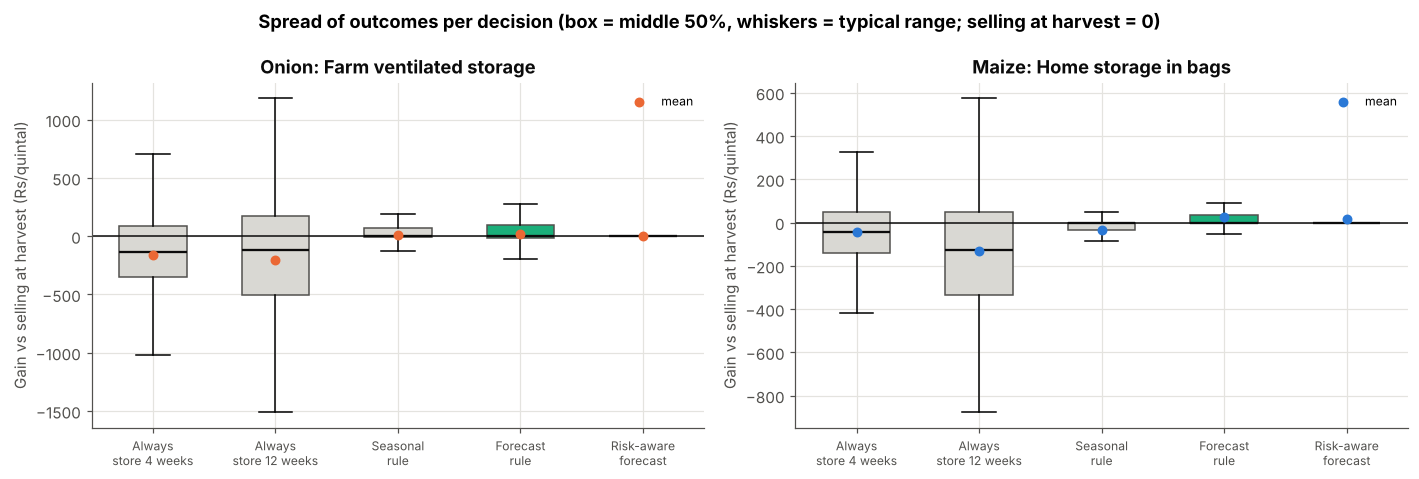

--- Onion: Farm ventilated storage ---


,rule,mean gain Rs/q,chance of doing worse than selling %,worst 5% (Rs/q),stored in % of events
11,Always store 12 weeks,-202.6,59.8,-1320.7,100.0
12,Seasonal rule,9.1,25.3,-538.8,55.1
13,Forecast rule,20.0,26.0,-508.5,56.9
14,Risk-aware forecast,5.2,0.1,0.0,1.8


--- Maize: Home storage in bags ---


,rule,mean gain Rs/q,chance of doing worse than selling %,worst 5% (Rs/q),stored in % of events
51,Always store 12 weeks,-133.2,67.9,-551.4,100.0
52,Seasonal rule,-32.7,28.2,-376.8,44.0
53,Forecast rule,26.7,19.1,-141.3,49.1
54,Risk-aware forecast,16.8,13.6,-83.9,34.3


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, crop in zip(axes, CROPS):
    res, P = simulate(events[crop], **SCENARIOS[crop][MAIN_SCENARIO[crop]])
    rules = ["Always store 4 weeks", "Always store 12 weeks", "Seasonal rule", "Forecast rule", "Risk-aware forecast"]
    data = [res[r][1] for r in rules]
    parts = ax.boxplot(data, tick_labels=[r.replace(" ", "\n", 1) for r in rules], widths=0.55, showfliers=False,
                       patch_artist=True, medianprops=dict(color=INK, linewidth=1.5))
    for patch, r in zip(parts["boxes"], rules):
        patch.set_facecolor({"Forecast rule": AQUA, "Risk-aware forecast": VIOLET}.get(r, "#d9d8d3")); patch.set_edgecolor(MUTED)
    ax.scatter(range(1, len(rules) + 1), [d.mean() for d in data], color=CROP_COLOR[crop], zorder=3, s=30, label="mean")
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_ylabel("Gain vs selling at harvest (Rs/quintal)"); ax.set_title(f"{crop}: {MAIN_SCENARIO[crop]}")
    ax.tick_params(axis="x", labelsize=8); ax.legend(frameon=False, fontsize=8)
fig.suptitle("Spread of outcomes per decision (box = middle 50%, whiskers = typical range; selling at harvest = 0)", fontweight="bold")
plt.tight_layout(); plt.show()

risk_cols = ["rule", "mean gain Rs/q", "chance of doing worse than selling %", "worst 5% (Rs/q)", "stored in % of events"]
for crop in CROPS:
    print(f"--- {crop}: {MAIN_SCENARIO[crop]} ---")
    display(summary[(summary["crop"] == crop) & (summary["scenario"] == MAIN_SCENARIO[crop])
                    & summary["rule"].isin(["Always store 12 weeks", "Seasonal rule", "Forecast rule", "Risk-aware forecast"])][risk_cols].round(1))

**Reading the risk.**
- Fixed storage habits have a very wide spread: storing onion for 12 weeks could gain over Rs 1,000 per quintal or lose
  over Rs 1,300, and it did worse than selling at harvest in about 60% of events.
- The forecast rule narrows the spread a lot, because it sells at harvest whenever storage looks unprofitable. Its
  worst 5% of outcomes are far less painful than those of the fixed rules.
- The **risk-aware forecast** goes further. For maize it keeps most of the gain (Rs 17 instead of 27 per quintal) while
  cutting the chance of a loss from 19% to 14% and halving the worst case. For onion in ventilated storage it almost
  never stores (2% of events): the forecast's 80% interval is wide (Notebook 5), so the pessimistic case nearly always
  loses more than 10%. It is then effectively "sell at harvest" with almost no risk.
- Which rule is best therefore depends on the farmer: one who can absorb losses may follow the plain forecast; one who
  cannot should use the risk-aware version.

## 7. Is the forecast rule's advantage statistically real?

Comparisons are **paired**: every rule is scored on the same events. Events in the same week share the same price
news, so each test uses **one value per decision week** (the average difference across markets that week).

- **H0:** the forecast rule's weekly mean gain is not higher than the comparison rule's.
- **H1:** it is higher (one-sided Wilcoxon signed-rank, α = 0.05).
- **Uncertainty:** a 95% confidence interval for the mean difference from a **cluster bootstrap over seasons**
  (whole harvest seasons resampled, 2,000 times), because a single good or bad year affects every market at once.

In [8]:
def season_bootstrap(diff, seasons, reps=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    groups = [diff[seasons == s] for s in np.unique(seasons)]
    means = [np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))]).mean() for _ in range(reps)]
    return np.percentile(means, [2.5, 97.5])

test_rows = []
for crop in CROPS:
    e = events[crop]
    for scen, params in SCENARIOS[crop].items():
        if scen.startswith("No costs"):
            continue
        res, P = simulate(e, **params)
        fixed = ["Always store 4 weeks", "Always store 8 weeks", "Always store 12 weeks"]
        best_fixed = max(fixed, key=lambda r: res[r][1].mean())
        for other in ["Sell at harvest", best_fixed, "Seasonal rule"]:
            diff = res["Forecast rule"][1] - res[other][1]
            weekly = pd.Series(diff).groupby(e["week"].to_numpy()).mean()
            w = stats.wilcoxon(weekly, alternative="greater") if (weekly != 0).any() else None
            lo, hi = season_bootstrap(diff, e["season"].to_numpy())
            by_season = pd.Series(diff).groupby(e["season"].to_numpy()).mean()
            test_rows.append({"crop": crop, "scenario": scen, "forecast rule vs": other,
                              "mean difference Rs/q": diff.mean(), "95% CI low": lo, "95% CI high": hi,
                              "seasons where forecast won": f"{(by_season > 0).sum()} of {len(by_season)}",
                              "weeks": len(weekly), "Wilcoxon p (weekly)": w.pvalue if w else np.nan})
tests = pd.DataFrame(test_rows)
tests.round(3)

,crop,scenario,forecast rule vs,mean difference Rs/q,95% CI low,95% CI high,seasons where forecast won,weeks,Wilcoxon p (weekly)
0,Onion,Farm ventilated storage,Sell at harvest,20.022,-105.442,164.134,3 of 6,79,0.517
1,Onion,Farm ventilated storage,Always store 4 weeks,184.537,147.944,220.991,6 of 6,79,0.000
2,Onion,Farm ventilated storage,Seasonal rule,10.958,-6.343,31.701,4 of 6,79,0.194
3,Onion,Well-managed storage,Sell at harvest,111.320,-95.757,354.838,4 of 6,79,0.020
4,Onion,Well-managed storage,Always store 12 weeks,139.700,58.392,212.938,5 of 6,79,0.000
5,Onion,Well-managed storage,Seasonal rule,19.718,-6.610,48.838,4 of 6,79,0.045
6,Onion,Cold storage,Sell at harvest,154.252,-97.523,455.489,4 of 6,79,0.013
7,Onion,Cold storage,Always store 12 weeks,115.126,50.463,174.839,5 of 6,79,0.001
8,Onion,Cold storage,Seasonal rule,26.073,-5.225,62.224,4 of 6,79,0.059
9,Maize,Poor home storage,Sell at harvest,11.270,-8.013,38.085,4 of 7,81,0.175


**Reading the tests.** The forecast rule is compared with three alternatives: selling at harvest, the **best**
fixed storage period for that scenario (chosen with hindsight, which favours the fixed rule), and the seasonal rule.
- **vs the best fixed storage period:** the forecast rule wins clearly in every scenario for both crops (confidence
  intervals entirely above 0, p ≤ 0.001, and it won in at least 5 of the 6 onion seasons and 6 of the 7 maize seasons).
- **vs the seasonal rule:** for **maize** the advantage is secure (Rs 17-82 per quintal, p ≤ 0.001, and the interval is
  above 0 in the bags and warehouse scenarios). For **onion** the forecast rule earned Rs 11-26 per quintal more on
  average, but the intervals include 0 and only the well-managed storage scenario reaches p < 0.05.
- **vs selling at harvest:** the forecast rule earned more on average in every scenario, but the season-bootstrap
  intervals are wide and include 0, because one bad season (when stored crops met a price fall) can wipe out the gains
  of good ones. With only 6-7 harvest seasons in the test period, this is the honest limit of what the data can show.
- In short: the evidence is strong that the forecast beats **storing by habit**, strong for maize that it beats
  **seasonal experience**, and suggestive but not conclusive for onion against seasonal experience and against simply
  selling at harvest.

## 8. Monte Carlo: what if the cost assumptions are wrong?

Storage losses, rent and interest rates are uncertain and differ between farmers. Instead of trusting one set of
values, **2,000 combinations** are drawn at random from wide ranges, and the whole simulation is rerun for each one:

| Parameter | Onion range | Maize range |
| --- | --- | --- |
| Loss per month | 1% to 12% | 0.25% to 3% |
| Rent, Rs per quintal per month | 0 to 60 | 0 to 15 |
| Interest per year | 4% to 12% | 4% to 12% |

For each draw the result of every rule is recorded. This answers: **across all plausible farm situations, how often is
the forecast rule the best real rule, and by how much?**

In [9]:
N_DRAWS = 2000
RANGES = {"Onion": dict(loss=(0.01, 0.12), rent=(0, 60), rate=(0.04, 0.12)),
          "Maize": dict(loss=(0.0025, 0.03), rent=(0, 15), rate=(0.04, 0.12))}
rng = np.random.default_rng(SEED)
mc_rows = []
for crop in CROPS:
    e = events[crop]
    for d in range(N_DRAWS):
        params = {k: rng.uniform(*v) for k, v in RANGES[crop].items()}
        res, P = simulate(e, **params)
        means = {rule: res[rule][1].mean() for rule in RULES}
        best_fixed = max(means[r] for r in ["Always store 4 weeks", "Always store 8 weeks", "Always store 12 weeks"])
        mc_rows.append({"crop": crop, "draw": d, **params, **means, "Best fixed rule": best_fixed})
mc = pd.DataFrame(mc_rows)

real_rules = ["Sell at harvest", "Best fixed rule", "Seasonal rule", "Forecast rule", "Risk-aware forecast"]
mc["best real rule"] = mc[real_rules].idxmax(axis=1)
mc["forecast vs seasonal"] = mc["Forecast rule"] - mc["Seasonal rule"]
mc["forecast vs best other"] = mc["Forecast rule"] - mc[["Sell at harvest", "Best fixed rule", "Seasonal rule"]].max(axis=1)

summary_mc = mc.groupby("crop").agg(
    draws=("draw", "size"),
    forecast_mean_gain=("Forecast rule", "mean"),
    forecast_positive_pct=("Forecast rule", lambda s: 100 * (s > 0).mean()),
    beats_seasonal_pct=("forecast vs seasonal", lambda s: 100 * (s > 0).mean()),
    beats_all_non_forecast_pct=("forecast vs best other", lambda s: 100 * (s > 0).mean()),
    advantage_median=("forecast vs best other", "median"),
    advantage_p5=("forecast vs best other", lambda s: np.percentile(s, 5)),
    advantage_p95=("forecast vs best other", lambda s: np.percentile(s, 95)))
display(summary_mc.round(1))
print("Which real rule was best, % of draws:")
display((pd.crosstab(mc["crop"], mc["best real rule"], normalize="index") * 100).round(1))

,draws,forecast_mean_gain,forecast_positive_pct,beats_seasonal_pct,beats_all_non_forecast_pct,advantage_median,advantage_p5,advantage_p95
crop,,,,,,,,
Maize,2000,20.2,100.0,100.0,100.0,18.7,8.5,36.7
Onion,2000,67.5,82.0,88.8,78.7,17.3,-11.2,28.8


Which real rule was best, % of draws:


best real rule,Forecast rule,Risk-aware forecast,Seasonal rule
crop,,,
Maize,99.9,0.1,0.0
Onion,78.0,18.8,3.2


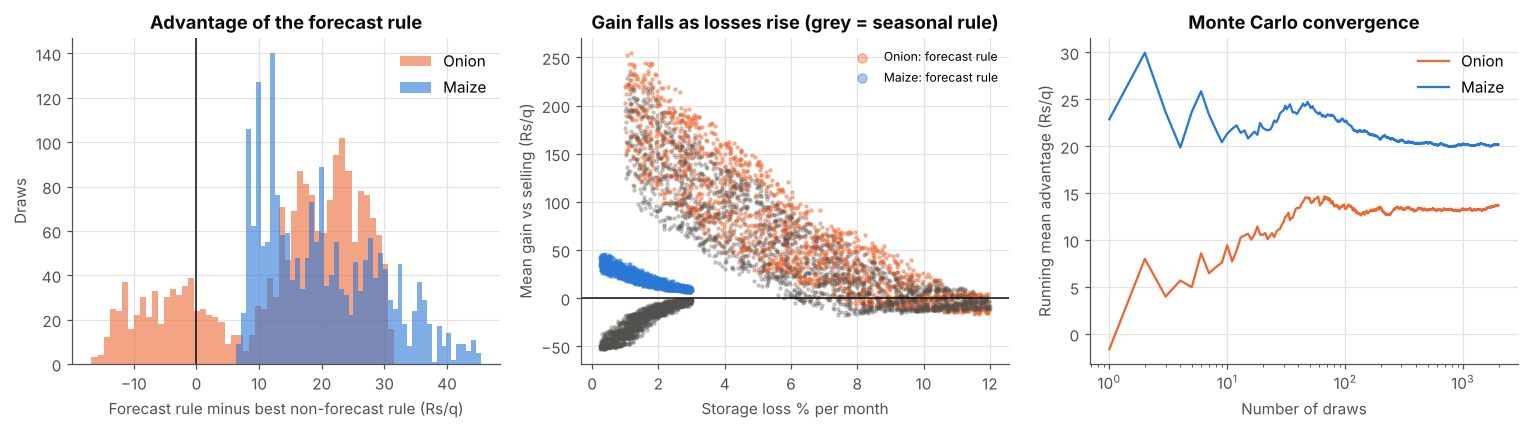

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for crop in CROPS:
    m = mc[mc["crop"] == crop]
    axes[0].hist(m["forecast vs best other"], bins=50, color=CROP_COLOR[crop], alpha=0.6, label=crop)
    axes[1].scatter(100 * m["loss"], m["Forecast rule"], s=4, alpha=0.4, color=CROP_COLOR[crop], label=f"{crop}: forecast rule")
    axes[1].scatter(100 * m["loss"], m["Seasonal rule"], s=4, alpha=0.25, color=MUTED)
    running = m["forecast vs best other"].expanding().mean()
    axes[2].plot(np.arange(1, len(m) + 1), running, color=CROP_COLOR[crop], linewidth=1.5, label=crop)
axes[0].axvline(0, color=INK, linewidth=1)
axes[0].set_xlabel("Forecast rule minus best non-forecast rule (Rs/q)"); axes[0].set_ylabel("Draws")
axes[0].set_title("Advantage of the forecast rule"); axes[0].legend(frameon=False)
axes[1].axhline(0, color=INK, linewidth=1)
axes[1].set_xlabel("Storage loss % per month"); axes[1].set_ylabel("Mean gain vs selling (Rs/q)")
axes[1].set_title("Gain falls as losses rise (grey = seasonal rule)"); axes[1].legend(frameon=False, fontsize=8, markerscale=3)
axes[2].set_xscale("log"); axes[2].set_xlabel("Number of draws"); axes[2].set_ylabel("Running mean advantage (Rs/q)")
axes[2].set_title("Monte Carlo convergence"); axes[2].legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading the Monte Carlo.**
- The left chart shows, over all 2,000 plausible farm situations, how much more the forecast rule earned than the best
  of the other real rules (selling at harvest, the best fixed period chosen with hindsight, or the seasonal rule).
  For **maize** the forecast rule was ahead in every draw (median advantage about Rs 19 per quintal). For **onion** it
  was ahead in about 79% of draws (median about Rs 17); the draws where it fell behind are those with very high
  losses, where the risk-aware forecast or simply selling at harvest is the better choice.
- The middle chart shows **why storage technology matters**: as losses per month rise, every rule's gain falls, and
  above a certain loss rate even the forecast can only recommend selling at harvest.
- The right chart confirms the Monte Carlo has **converged**: the running mean is flat long before 2,000 draws, so more
  draws would not change the conclusion.

## 9. Sensitivity: which rule is best under which conditions?

A grid of storage loss and rent (interest fixed at 7%). Each cell shows the forecast rule's mean gain, and the letter
names the best real rule there: **S** = sell at harvest, **F** = forecast rule, **R** = risk-aware forecast,
**X** = a fixed storage period, **N** = seasonal rule.

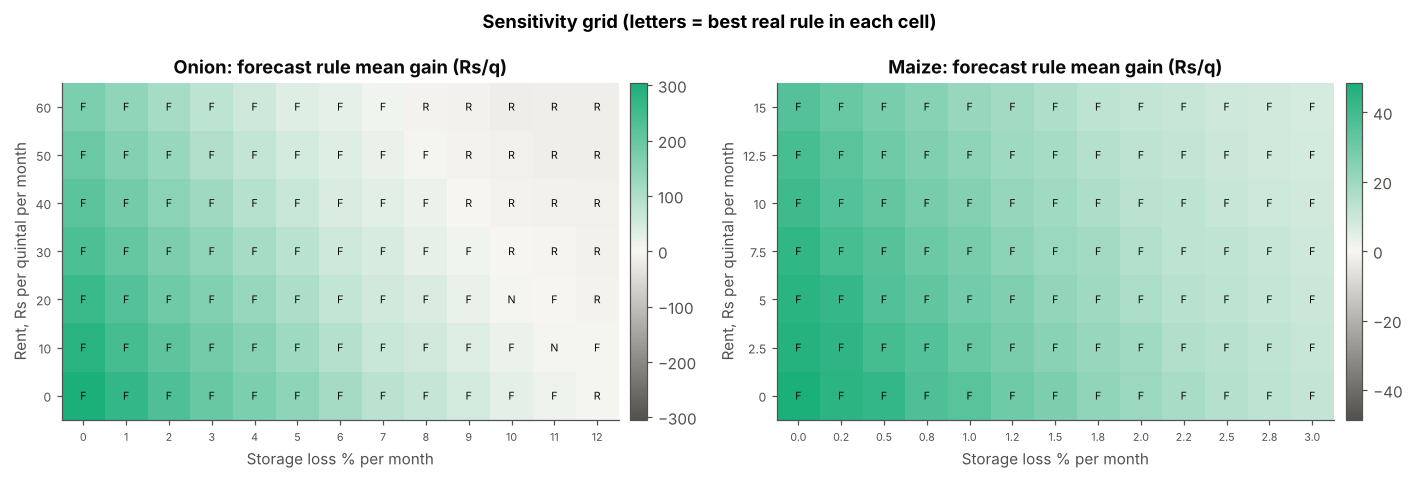

Share of grid cells in which each rule is best (%):


best rule,Forecast rule,Risk-aware forecast,Seasonal rule
crop,,,
Maize,100.0,0.0,0.0
Onion,78.0,19.8,2.2


In [11]:
GRID = {"Onion": (np.linspace(0, 0.12, 13), np.array([0, 10, 20, 30, 40, 50, 60])),
        "Maize": (np.linspace(0, 0.03, 13), np.array([0, 2.5, 5, 7.5, 10, 12.5, 15]))}
letters = {"Sell at harvest": "S", "Forecast rule": "F", "Risk-aware forecast": "R", "Best fixed rule": "X", "Seasonal rule": "N"}
cmap = LinearSegmentedColormap.from_list("loss_gain", [MUTED, "#f7f6f2", AQUA])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sens_rows = []
for ax, crop in zip(axes, CROPS):
    losses, rents = GRID[crop]
    val = np.zeros((len(rents), len(losses)))
    for i, rent in enumerate(rents):
        for j, loss in enumerate(losses):
            res, P = simulate(events[crop], loss=loss, rent=rent, rate=0.07)
            means = {r: res[r][1].mean() for r in RULES}
            means["Best fixed rule"] = max(means[r] for r in ["Always store 4 weeks", "Always store 8 weeks", "Always store 12 weeks"])
            best = max(["Sell at harvest", "Best fixed rule", "Seasonal rule", "Forecast rule", "Risk-aware forecast"], key=means.get)
            val[i, j] = means["Forecast rule"]
            ax.text(j, i, letters[best], ha="center", va="center", fontsize=7, color=INK)
            sens_rows.append({"crop": crop, "loss": loss, "rent": rent, "forecast gain": means["Forecast rule"], "best rule": best})
    lim = np.abs(val).max()
    im = ax.imshow(val, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto", origin="lower")
    ax.set_xticks(range(len(losses))); ax.set_xticklabels([f"{100 * l:.1f}" if crop == "Maize" else f"{100 * l:.0f}" for l in losses], fontsize=7)
    ax.set_yticks(range(len(rents))); ax.set_yticklabels([f"{r:g}" for r in rents], fontsize=8)
    ax.set_xlabel("Storage loss % per month"); ax.set_ylabel("Rent, Rs per quintal per month"); ax.grid(False)
    ax.set_title(f"{crop}: forecast rule mean gain (Rs/q)")
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
fig.suptitle("Sensitivity grid (letters = best real rule in each cell)", fontweight="bold")
plt.tight_layout(); plt.show()
sensitivity = pd.DataFrame(sens_rows)
print("Share of grid cells in which each rule is best (%):")
(pd.crosstab(sensitivity["crop"], sensitivity["best rule"], normalize="index") * 100).round(1)

**Reading the grid.** The forecast rule's gain shrinks as losses and rent rise. Unlike a fixed habit it can fall back
to selling at harvest, so even in the worst onion cells it loses only a little (about Rs 15 per quintal at most).
Forecast-based rules (F or R) are the best real rule in almost every cell. For onion with losses above about 8% a
month and high rent, the **risk-aware** forecast takes over: when storage is that costly, the safest choice is
usually to sell.

## 10. One farmer, one decision: the dashboard's core calculation

The rules above use one forecast number. A farmer also needs to see the **range** of outcomes. For a single decision,
future prices are drawn 5,000 times from a distribution centred on the forecast, with the spread of the conformal 80%
interval (Notebook 5), extended smoothly beyond the 10th and 90th percentiles, and the net revenue of each option is computed for a farmer with **50 quintals**.
This is the calculation the dashboard will run.

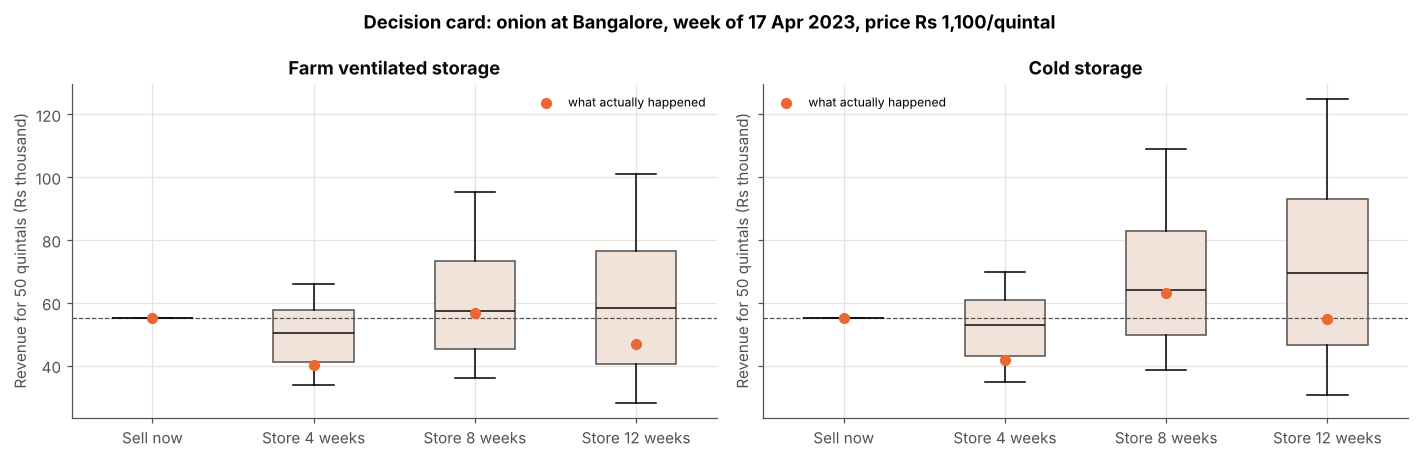

,scenario,option,median revenue Rs,chance better than selling now %,10th percentile Rs,90th percentile Rs
0,Farm ventilated storage,Sell now,55000.0,0.0,55000.0,55000.0
1,Farm ventilated storage,Store 4 weeks,50399.0,34.0,36726.0,62522.0
2,Farm ventilated storage,Store 8 weeks,57419.0,54.0,39556.0,85788.0
3,Farm ventilated storage,Store 12 weeks,58287.0,54.0,32906.0,90144.0
4,Cold storage,Sell now,55000.0,0.0,55000.0,55000.0
5,Cold storage,Store 4 weeks,52869.0,43.0,37977.0,66072.0
6,Cold storage,Store 8 weeks,64169.0,65.0,42978.0,97823.0
7,Cold storage,Store 12 weeks,69558.0,65.0,36763.0,110719.0


In [12]:
def sample_log_change(q10, q50, q90, n, rng, centre=None):
    # draw from a distribution with the given 10th, 50th and 90th percentiles (piecewise-linear quantile function).
    # The spread comes from the quantile models; the distribution is shifted so that its median equals the main
    # model's forecast (centre), so the card agrees with the forecast rule.
    q10, q50, q90 = np.sort([q10, q50, q90])
    if centre is not None:
        q10, q90, q50 = q10 - q50 + centre, q90 - q50 + centre, centre
    u = rng.uniform(0.005, 0.995, n)
    low = q50 - (0.5 - u) / 0.4 * (q50 - q10)
    high = q50 + (u - 0.5) / 0.4 * (q90 - q50)
    return np.where(u < 0.5, low, high)

def decision_card(row, params, quintals=50, n=5000, seed=SEED):
    rng = np.random.default_rng(seed)
    P = row["price_filled"]
    out = {"Sell now": np.full(n, P * quintals)}
    for k, h in enumerate(H):
        x = sample_log_change(row[f"q10_{h}w"], row[f"q50_{h}w"], row[f"q90_{h}w"], n, rng, centre=row[f"pred_{h}w_best"])
        gain = net_gain(np.array([P]), np.tile(x[:, None], (1, 3)), **params)[:, k]
        out[f"Store {h} weeks"] = (P + gain) * quintals
    actual = [P * quintals] + [(P + net_gain(np.array([P]), np.array([[row[f"target_{h}w"] for h in H]]), **params)[0, k]) * quintals
                               for k in range(3)]
    return out, actual

e = events["Onion"]
example = e[(e["market"] == "Bangalore") & (e["season"] == 2023)].iloc[len(e[(e["market"] == "Bangalore") & (e["season"] == 2023)]) // 2]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
card_rows = []
for ax, scen in zip(axes, ["Farm ventilated storage", "Cold storage"]):
    sims, actual = decision_card(example, SCENARIOS["Onion"][scen])
    names = list(sims)
    ax.boxplot([sims[k] / 1000 for k in names], tick_labels=names, widths=0.5, showfliers=False,
               patch_artist=True, boxprops=dict(facecolor="#f2e3da", edgecolor=MUTED), medianprops=dict(color=INK))
    ax.scatter(range(1, 5), np.array(actual) / 1000, color=ORANGE, zorder=3, s=40, label="what actually happened")
    ax.axhline(sims["Sell now"][0] / 1000, color=MUTED, linewidth=0.8, linestyle="--")
    ax.set_title(scen); ax.set_ylabel("Revenue for 50 quintals (Rs thousand)"); ax.legend(frameon=False, fontsize=8)
    for k in names:
        card_rows.append({"scenario": scen, "option": k, "median revenue Rs": np.median(sims[k]),
                          "chance better than selling now %": 100 * np.mean(sims[k] > sims["Sell now"][0]),
                          "10th percentile Rs": np.percentile(sims[k], 10), "90th percentile Rs": np.percentile(sims[k], 90)})
fig.suptitle(f"Decision card: onion at {example['market']}, week of {example['week']:%d %b %Y}, "
             f"price Rs {example['price_filled']:,.0f}/quintal", fontweight="bold")
plt.tight_layout(); plt.show()
pd.DataFrame(card_rows).round(0)

**Reading the card.** Each box is the range of revenue the forecast considered likely for that option; the dot is
what really happened.
- The same forecast gives different odds depending on the storage: storing 12 weeks had about a 54% chance of beating
  selling now with ventilated storage (barely better than a coin toss), and about 65% with cold storage.
- In this case the 12-week outcome turned out **worse** than selling now, while 8 weeks would have paid off with cold
  storage. A forecast gives **odds, not certainty**. Showing the full range, not just one number, is what lets a
  farmer judge whether they can afford the bad case.
- This is why the dashboard asks the farmer about their storage before giving advice.

## 11. The value of information and of better storage

Two numbers matter to policy makers and farmer producer organisations (FPOs):
- **Value of the forecast** = forecast rule − best non-forecast rule: what a good price forecast is worth per quintal.
- **Value of perfect information** = perfect foresight − forecast rule: how much more a better forecast could ever add.
- **Value of better storage** = the forecast rule's gain in a better storage scenario − its gain in the main scenario:
  an upper limit on what a farmer could afford to pay extra for that storage.

In [13]:
val_rows = []
for crop in CROPS:
    s = summary[summary["crop"] == crop].pivot(index="scenario", columns="rule", values="mean gain Rs/q")
    for scen in SCENARIOS[crop]:
        r = s.loc[scen]
        best_other = max(r["Sell at harvest"], r["Always store 4 weeks"], r["Always store 8 weeks"], r["Always store 12 weeks"], r["Seasonal rule"])
        val_rows.append({"crop": crop, "scenario": scen, "forecast rule Rs/q": r["Forecast rule"],
                         "value of the forecast Rs/q": r["Forecast rule"] - best_other,
                         "value of perfect information Rs/q": r["Perfect foresight"] - r["Forecast rule"],
                         "value of this storage vs main scenario Rs/q": r["Forecast rule"] - s.loc[MAIN_SCENARIO[crop], "Forecast rule"]})
values = pd.DataFrame(val_rows)
values.round(1)

,crop,scenario,forecast rule Rs/q,value of the forecast Rs/q,value of perfect information Rs/q,value of this storage vs main scenario Rs/q
0,Onion,No costs (price effect only),322.1,27.4,144.2,302.1
1,Onion,Farm ventilated storage,20.0,11.0,173.0,0.0
2,Onion,Well-managed storage,111.3,19.7,179.1,91.3
3,Onion,Cold storage,154.3,26.1,186.4,134.2
4,Maize,No costs (price effect only),54.1,54.1,74.9,27.4
5,Maize,Poor home storage,11.3,11.3,54.1,-15.4
6,Maize,Home storage in bags,26.7,26.7,60.1,0.0
7,Maize,Warehouse,32.5,32.5,63.2,5.8


## 12. Conclusions for RQ4, and what a stakeholder can do with them

**What the simulation shows (test period 2020-2026, decisions in the harvest window):**
1. **Fixed storage habits are a bad bet once storage losses are counted.** Prices do rise after the onion harvest, but
   onions in a typical ventilated store lose so much weight that "always store for 3 months" lost about Rs 200 per
   quintal on average. Fixed storage lost money for maize in every scenario.
2. **Following the forecast gave the highest average gain of all real rules in every storage scenario, for both
   crops**, by storing only when the expected rise covers the losses. Against storing by habit the advantage is
   large and statistically secure.
3. **For maize, only the forecast-based rules made money**, and the advantage over seasonal experience is
   statistically secure (Rs 17-82 per quintal). For onion the forecast beat seasonal experience by Rs 11-26 per quintal
   on average, but with only six harvest seasons that margin is not statistically conclusive. This limit should be
   stated in the report.
4. **Storage technology changes the answer more than the forecast does.** The forecast rule earned about Rs 20 per
   quintal with ventilated farm storage, but about Rs 154 with cold storage. The forecast alone is worth Rs 11-26 per
   quintal for onion; better storage is worth up to about Rs 134 more.
5. **Accuracy is not the same as value**, as Gammelli et al. and Theodorou et al. found outside agriculture: a
   forecast with about 32% error (Notebook 5) still adds value, because the decision only needs to know whether the
   rise will beat the cost, not the exact price. The Monte Carlo shows the conclusion holds for maize under every
   plausible cost assumption, and for onion under about four out of five.

**Decisions a stakeholder could make**
- **A farmer**: do not store by habit. Store only when the forecast's expected rise beats your storage losses; if you
  cannot afford a bad outcome, use the risk-aware rule.
- **An FPO or the state agriculture department**: combining a price forecast with better storage (cold or
  well-managed ventilated stores) gives far more than either alone; Section 11 gives an upper limit on what that
  storage is worth per quintal.

**What this simulation does not show (assumptions and limits)**
- Storage losses, rent and interest are **assumptions** based on published figures, not measurements of Karnataka
  farms; Sections 8-9 show how the results change across wide ranges.
- The simulation assumes one farmer's sale does not move the market price. If every farmer followed the same forecast
  and stored at once, prices would behave differently.
- Results are from one run of history (2020-2026, six harvest seasons) and the core markets only. They are evidence of
  value under these conditions, **not proof of a causal income effect** for real farmers; that would need a field trial.
- Losses are assumed constant per month; in reality onion losses rise in the monsoon months.

In [14]:
summary.to_csv("../data/simulation_summary.csv", index=False)
out = []
for crop in CROPS:
    res, P = simulate(events[crop], **SCENARIOS[crop][MAIN_SCENARIO[crop]])
    e = events[crop][["commodity", "market", "district", "division", "week", "season", "price_filled"]].copy()
    for rule in RULES:
        e[f"action: {rule}"] = np.array([0, 4, 8, 12])[res[rule][0]]
        e[f"gain: {rule}"] = res[rule][1]
    out.append(e)
pd.concat(out).to_csv("../data/simulation_events.csv", index=False)
mc.to_csv("../data/montecarlo_draws.csv", index=False)
tests.to_csv("../data/simulation_tests.csv", index=False)
print("Saved data/simulation_summary.csv, data/simulation_events.csv, data/montecarlo_draws.csv, data/simulation_tests.csv")

Saved data/simulation_summary.csv, data/simulation_events.csv, data/montecarlo_draws.csv, data/simulation_tests.csv
